# 02 · Modelos de demanda: 5 modelos vs. la heurística actual — DataByte / RescateAlimento
**Capstone · Etapa 4 (Modelo de decisión): "transformar datos en acción" con Machine Learning**

## ¿Qué piden los apuntes?
* §2: probar **5 modelos** — 2 clásicos, 2 de ensamble y 1 red neuronal (MLP) — ajustar hiperparámetros (Random/Grid Search) y elegir por una métrica (*AutoML rudimentario*, pero "con respeto y recato": entendiendo qué se hace).
* §3: **antes de modelar, probar reglas/heurísticas** que funcionen a nivel de negocio. Ese es nuestro `modelo_score.py` (v02.7): su componente *Ritmo* es una **media móvil de 7 días**. Esa es la vara que el ML tiene que superar.

## ¿Qué problema le damos al ML?
> **Predecir cuántas unidades se venderán de un producto mañana** (por comercio).

Es el eslabón débil del Score: el *ritmo de venta* decide cuánta **merma** se proyecta, y de ahí salen el puntaje y el descuento sugerido. Si el ML predice mejor que la media móvil, el Score recomienda mejor.

## Cómo trabajamos (reglas para que el resultado sea honesto)
1. **Partición temporal** (entrenar con el pasado, evaluar con las últimas 3 semanas). *Nunca* mezclar al azar: en series de tiempo se "espiaría el futuro".
2. **Validación cruzada temporal** (`TimeSeriesSplit`) para elegir hiperparámetros, y el **test** se mira **una sola vez** al final.
3. Se elige por **MAE en validación cruzada** (no por el test, para no "hacer trampa").
4. Se compara siempre contra las **heurísticas** (ayer, hace 7 días, media móvil 7). Un modelo complejo que no las supera **no se usa**.

> ⚠️ Con datos **simulados** el resultado demuestra que el pipeline funciona, no el rendimiento real. Con datos reales se vuelve a ejecutar tal cual.

## 0. Configuración y datos

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 160)
SEED = 42
datos = pd.read_csv("data/dataset_modelado.csv", parse_dates=["fecha"], dtype={"telegram_id": str, "ean": str})
datos = datos.sort_values("fecha").reset_index(drop=True)      # orden cronológico: imprescindible para TimeSeriesSplit
print(f"{len(datos):,} filas · {datos.fecha.min():%d/%m/%Y} → {datos.fecha.max():%d/%m/%Y} · fuente: {datos.get('fuente', pd.Series(['?'])).iloc[0]}")

3,312 filas · 16/08/2026 → 15/11/2026 · fuente: SIMULADO


## 1. Variables (las que decidimos en el notebook 01) y partición temporal

In [2]:
NUMERICAS   = ["precio_rel","dias_al_vencimiento","stock_inicial_dia","dow","es_finde","dia_mes",
               "ventas_lag1","ventas_lag7","media_movil_7","media_movil_28"]
CATEGORICAS = ["categoria","ean","telegram_id"]
OBJETIVO    = "unidades_vendidas"

DIAS_TEST = 21                                             # las últimas 3 semanas son el examen final
corte = datos.fecha.max() - pd.Timedelta(days=DIAS_TEST)
train, test = datos[datos.fecha <= corte], datos[datos.fecha > corte]
Xtr, ytr = train[NUMERICAS + CATEGORICAS], train[OBJETIVO]
Xte, yte = test[NUMERICAS + CATEGORICAS],  test[OBJETIVO]
print(f"Entrenamiento: {len(train):,} filas (hasta {corte:%d/%m/%Y})  |  Test: {len(test):,} filas (últimas {DIAS_TEST} días)")

cv = TimeSeriesSplit(n_splits=4)                           # cada fold entrena con el pasado y valida en el futuro inmediato

Entrenamiento: 2,556 filas (hasta 25/10/2026)  |  Test: 756 filas (últimas 21 días)


## 2. Heurísticas (lo que ya tenemos) — la vara a superar
Siguiendo el flujo de los apuntes (*reglas simples → heurística → modelo*):
| Heurística | Idea | ¿Dónde está en el bot? |
|---|---|---|
| **Ayer** | mañana vendo lo mismo que hoy | — |
| **Mismo día de la semana pasada** | captura la estacionalidad semanal | — |
| **Media móvil 7 días** | promedio de la última semana | ✅ componente *Ritmo* del Score (v02.7) |

In [3]:
def metricas(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p)), "R2": r2_score(y, p)}

heuristicas = {
    "Heurística: ayer":              test.ventas_lag1,
    "Heurística: mismo día sem. pasada": test.ventas_lag7,
    "Heurística: media móvil 7 (Score actual)": test.media_movil_7,
}
tabla = pd.DataFrame({k: metricas(yte, v) for k, v in heuristicas.items()}).T
tabla["tipo"] = "heurística"
mae_base = tabla.loc["Heurística: media móvil 7 (Score actual)", "MAE"]
print(f"Error de la heurística actual (media móvil 7): MAE = {mae_base:.2f} unidades/día")
tabla.round(3)

Error de la heurística actual (media móvil 7): MAE = 3.04 unidades/día


,MAE,RMSE,R2,tipo
Heurística: ayer,3.931,5.529,0.312,heurística
Heurística: mismo día sem. pasada,3.995,5.540,0.309,heurística
Heurística: media móvil 7 (Score actual),3.045,4.318,0.580,heurística


## 3. Los 5 modelos
Todos comparten el **mismo preprocesamiento** dentro de un `Pipeline` (así no hay fuga de datos entre entrenamiento y validación):
* variables numéricas → escaladas (`StandardScaler`; los árboles no lo necesitan pero no les hace daño),
* variables categóricas → `OneHotEncoder` (una columna 0/1 por categoría).

| # | Modelo | Familia | Qué hace en una línea | Búsqueda de hiperparámetros |
|---|---|---|---|---|
| 1 | **Ridge** | Clásico (regresión lineal regularizada) | Una fórmula lineal; el `alpha` penaliza coeficientes grandes | Grid Search |
| 2 | **K-Vecinos (KNN)** | Clásico (basado en distancia) | Predice con el promedio de los *k* casos más parecidos | Grid Search |
| 3 | **Random Forest** | Ensamble (bagging de árboles) | Cientos de árboles que "votan" | Random Search |
| 4 | **Gradient Boosting** | Ensamble (boosting; mismo principio que XGBoost) | Árboles en serie, cada uno corrige el error del anterior | Random Search |
| 5 | **MLP** | Red neuronal | Capas de neuronas; capta relaciones muy curvas pero necesita más datos | Random Search |

> *Sobre XGBoost*: los apuntes lo nombran. Usamos `GradientBoostingRegressor` de scikit-learn (mismo algoritmo base, sin instalar nada extra); cambiarlo por `xgboost.XGBRegressor` es una línea si se instala la librería.

In [4]:
prep = ColumnTransformer([
    ("num", StandardScaler(), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS),
])

def pipe(modelo):
    return Pipeline([("prep", prep), ("modelo", modelo)])

# (nombre, familia, pipeline, espacio de búsqueda, tipo de búsqueda)
CANDIDATOS = [
    ("Ridge", "clásico", pipe(Ridge()),
     {"modelo__alpha": [0.01, 0.1, 1, 10, 100]}, "grid"),
    ("KNN", "clásico", pipe(KNeighborsRegressor()),
     {"modelo__n_neighbors": [5, 10, 20, 40], "modelo__weights": ["uniform", "distance"]}, "grid"),
    ("Random Forest", "ensamble", pipe(RandomForestRegressor(random_state=SEED, n_jobs=-1)),
     {"modelo__n_estimators": [100, 200, 300], "modelo__max_depth": [6, 10, 16, None],
      "modelo__min_samples_leaf": [1, 3, 5, 10]}, "random"),
    ("Gradient Boosting", "ensamble", pipe(GradientBoostingRegressor(random_state=SEED)),
     {"modelo__n_estimators": [100, 200, 300], "modelo__learning_rate": [0.03, 0.05, 0.1],
      "modelo__max_depth": [2, 3, 4], "modelo__subsample": [0.7, 0.85, 1.0]}, "random"),
    ("MLP (red neuronal)", "red neuronal",
     Pipeline([("prep", prep), ("modelo", TransformedTargetRegressor(
         regressor=MLPRegressor(max_iter=600, early_stopping=True, random_state=SEED),
         transformer=StandardScaler()))]),
     {"modelo__regressor__hidden_layer_sizes": [(32,), (64,), (64, 32), (128, 64)],
      "modelo__regressor__alpha": [1e-4, 1e-3, 1e-2], "modelo__regressor__learning_rate_init": [1e-3, 3e-3]}, "random"),
]
print(len(CANDIDATOS), "modelos candidatos")

5 modelos candidatos


## 4. Entrenamiento y selección (AutoML rudimentario, entendido)
Para cada modelo se prueban combinaciones de hiperparámetros con **validación cruzada temporal** y se guarda la mejor
según **MAE** (error absoluto medio: *"en promedio me equivoco en X unidades por día"*; fácil de explicarle a un comerciante).

In [5]:
resultados, entrenados = [], {}
for nombre, familia, pipeline, espacio, tipo in CANDIDATOS:
    t0 = time.time()
    if tipo == "grid":
        buscador = GridSearchCV(pipeline, espacio, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    else:
        buscador = RandomizedSearchCV(pipeline, espacio, n_iter=10, cv=cv, scoring="neg_mean_absolute_error",
                                      n_jobs=-1, random_state=SEED)
    buscador.fit(Xtr, ytr)
    pred = np.clip(buscador.predict(Xte), 0, None)               # no existen ventas negativas
    m = metricas(yte, pred)
    resultados.append({"modelo": nombre, "familia": familia, "MAE_cv": -buscador.best_score_,
                       "MAE_test": m["MAE"], "RMSE_test": m["RMSE"], "R2_test": m["R2"],
                       "seg": time.time() - t0, "mejores_params": {k.split("__")[-1]: v for k, v in buscador.best_params_.items()}})
    entrenados[nombre] = (buscador.best_estimator_, pred)
    print(f"✔ {nombre:<20} MAE cv={-buscador.best_score_:.3f} | test={m['MAE']:.3f} | {time.time()-t0:.0f}s")

✔ Ridge                MAE cv=3.111 | test=2.825 | 1s


✔ KNN                  MAE cv=3.175 | test=2.932 | 0s


✔ Random Forest        MAE cv=2.952 | test=2.644 | 21s


✔ Gradient Boosting    MAE cv=2.818 | test=2.584 | 8s


✔ MLP (red neuronal)   MAE cv=3.135 | test=2.956 | 4s


## 5. Comparación de resultados
Elegimos el ganador por **MAE de validación cruzada** (no por el test). El test es el "examen final" y se usa para informar.

,tipo,MAE_cv,MAE_test,RMSE_test,R2_test,mejora_vs_Score_actual_%
Gradient Boosting,ensamble,2.818,2.584,3.511,0.723,15.1
Random Forest,ensamble,2.952,2.644,3.608,0.707,13.2
Ridge,clásico,3.111,2.825,3.886,0.660,7.2
KNN,clásico,3.175,2.932,4.015,0.637,3.7
MLP (red neuronal),red neuronal,3.135,2.956,3.999,0.640,2.9
Heurística: media móvil 7 (Score actual),heurística,NaN,3.045,4.318,0.580,0.0
Heurística: ayer,heurística,NaN,3.931,5.529,0.312,-29.1
Heurística: mismo día sem. pasada,heurística,NaN,3.995,5.540,0.309,-31.2



🏆 Ganador por validación cruzada: Gradient Boosting
Mejores hiperparámetros: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.03}


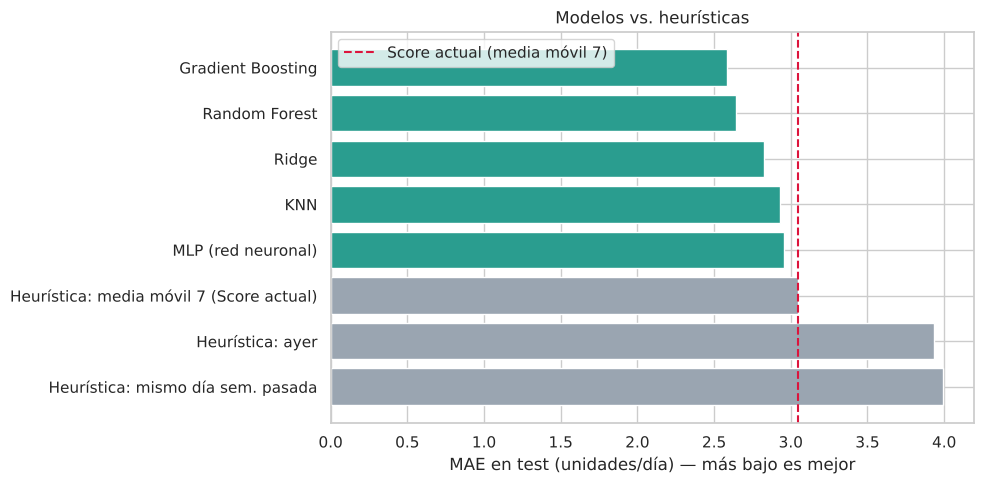

In [6]:
res = pd.DataFrame(resultados).set_index("modelo")
ganador = res.MAE_cv.idxmin()
comparacion = pd.concat([tabla.rename(columns={"MAE": "MAE_test", "RMSE": "RMSE_test", "R2": "R2_test"}),
                         res[["familia","MAE_cv","MAE_test","RMSE_test","R2_test"]].rename(columns={"familia": "tipo"})])
comparacion = comparacion[["tipo","MAE_cv","MAE_test","RMSE_test","R2_test"]]
comparacion["mejora_vs_Score_actual_%"] = ((mae_base - comparacion.MAE_test) / mae_base * 100).round(1)
display(comparacion.round(3).sort_values("MAE_test"))
print(f"\n🏆 Ganador por validación cruzada: {ganador}")
print("Mejores hiperparámetros:", res.loc[ganador, "mejores_params"])
comparacion.round(4).to_csv("data/resultados_modelos.csv")

fig, ax = plt.subplots(figsize=(10, 5))
orden = comparacion.sort_values("MAE_test")
colores = ["#9aa5b1" if t == "heurística" else "#2a9d8f" for t in orden.tipo]
ax.barh(orden.index, orden.MAE_test, color=colores); ax.invert_yaxis()
ax.axvline(mae_base, color="crimson", ls="--", label="Score actual (media móvil 7)")
ax.set_xlabel("MAE en test (unidades/día) — más bajo es mejor"); ax.set_title("Modelos vs. heurísticas"); ax.legend()
plt.tight_layout(); plt.show()

### 5.1 ¿Cómo se ve la predicción? (modelo ganador, total diario del test)

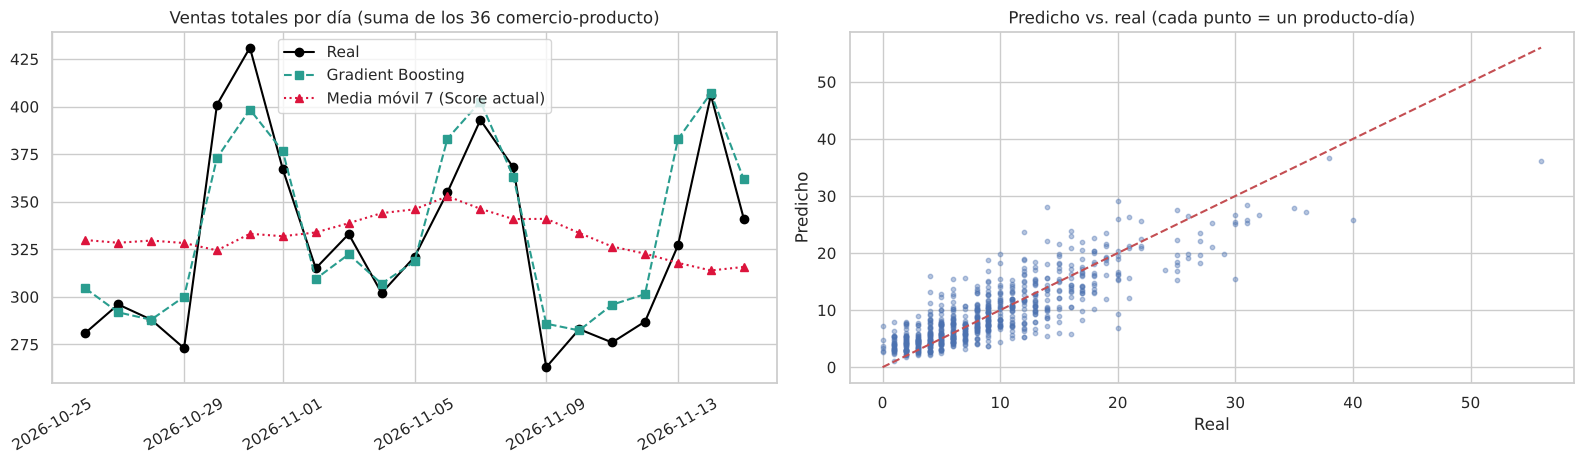

In [7]:
mejor, pred_mejor = entrenados[ganador]
vis = test[["fecha", OBJETIVO]].assign(pred=pred_mejor, media_movil=test.media_movil_7.values)
dia = vis.groupby("fecha").sum()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
ax[0].plot(dia.index, dia[OBJETIVO], "o-", label="Real", color="black")
ax[0].plot(dia.index, dia.pred, "s--", label=f"{ganador}", color="#2a9d8f")
ax[0].plot(dia.index, dia.media_movil, "^:", label="Media móvil 7 (Score actual)", color="crimson")
ax[0].set_title("Ventas totales por día (suma de los 36 comercio-producto)"); ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)
ax[1].scatter(vis[OBJETIVO], vis.pred, s=10, alpha=.4); lim = vis[OBJETIVO].max()
ax[1].plot([0, lim], [0, lim], "r--"); ax[1].set_xlabel("Real"); ax[1].set_ylabel("Predicho"); ax[1].set_title("Predicho vs. real (cada punto = un producto-día)")
plt.tight_layout(); plt.show()

## 6. ¿Qué mira el modelo? (importancia de variables)
No se usa como caja negra (advertencia de los apuntes): medimos con **importancia por permutación** cuánto empeora el error
si desordenamos una variable. Cuanto más empeora, más la usa el modelo.

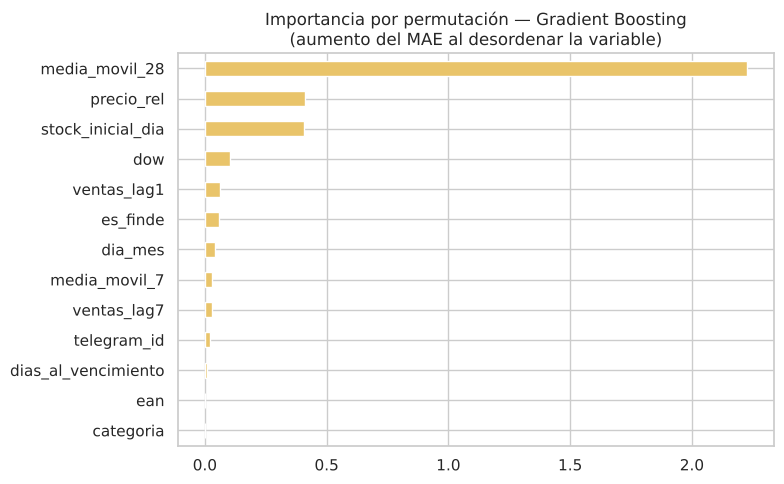

media_movil_28       2.226
precio_rel           0.410
stock_inicial_dia    0.407
dow                  0.101
ventas_lag1          0.063
es_finde             0.060


In [8]:
imp = permutation_importance(mejor, Xte, yte, scoring="neg_mean_absolute_error", n_repeats=8, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=Xte.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 5)); imp.plot.barh(ax=ax, color="#e9c46a")
ax.set_title(f"Importancia por permutación — {ganador}\n(aumento del MAE al desordenar la variable)"); plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(3).head(6).to_string())

## 7. Error por categoría de producto (¿dónde falla?)

In [9]:
por_cat = (test.assign(error=(pd.Series(pred_mejor, index=test.index) - test[OBJETIVO]).abs(),
                       error_base=(test.media_movil_7 - test[OBJETIVO]).abs())
           .groupby("categoria")[["error", "error_base"]].mean().rename(columns={"error": f"MAE {ganador}", "error_base": "MAE media móvil 7"}))
por_cat["mejora_%"] = ((por_cat.iloc[:, 1] - por_cat.iloc[:, 0]) / por_cat.iloc[:, 1] * 100).round(1)
por_cat.round(2)

,MAE Gradient Boosting,MAE media móvil 7,mejora_%
categoria,,,
Bebidas,3.02,3.67,17.8
Congelados,2.11,2.35,10.3
Fiambres,2.00,2.43,17.9
Frescos,2.29,2.54,9.8
Lacteos,2.79,3.24,14.0
Panificados,3.51,4.34,19.2


## 8. Decisión: ¿integramos el ML al bot?
Regla de decisión **escrita antes de ver el resultado** (para no justificar lo que ya pasó): se integra solo si el mejor modelo
reduce el MAE de la heurística actual **al menos un 5 %** en el test **y** también gana en validación cruzada.

In [10]:
mejora = (mae_base - res.loc[ganador, "MAE_test"]) / mae_base * 100
print(f"Mejora del {ganador} sobre la media móvil 7: {mejora:.1f} %")
if mejora >= 5:
    veredicto = "INTEGRAR"
    print("✅ VEREDICTO: INTEGRAR como componente 'Ritmo' del Score (en reemplazo de la media móvil), manteniendo la media móvil como respaldo cuando falten datos.")
else:
    veredicto = "MANTENER_HEURISTICA"
    print("⛔ VEREDICTO: MANTENER la media móvil. El ML no justifica su complejidad todavía; seguir juntando datos.")

if datos["fuente"].iloc[0] == "SIMULADO":
    print("⚠️ Con datos SIMULADOS el veredicto es PROVISORIO: valida el procedimiento, no el rendimiento real. Re-ejecutar con Ventas_Registradas real.")

# Guardamos el pipeline completo (preprocesamiento + modelo) y la lista de variables para el notebook 03.
joblib.dump(mejor, "models/modelo_demanda.joblib")
json.dump({"modelo": ganador, "numericas": NUMERICAS, "categoricas": CATEGORICAS, "mae_test": float(res.loc[ganador, "MAE_test"]),
           "mae_media_movil": float(mae_base), "mejora_pct": float(mejora), "veredicto": veredicto},
          open("models/modelo_demanda.json", "w"), indent=2)
print("Guardado: models/modelo_demanda.joblib y models/modelo_demanda.json")

Mejora del Gradient Boosting sobre la media móvil 7: 15.1 %
✅ VEREDICTO: INTEGRAR como componente 'Ritmo' del Score (en reemplazo de la media móvil), manteniendo la media móvil como respaldo cuando falten datos.
⚠️ Con datos SIMULADOS el veredicto es PROVISORIO: valida el procedimiento, no el rendimiento real. Re-ejecutar con Ventas_Registradas real.
Guardado: models/modelo_demanda.joblib y models/modelo_demanda.json


## 9. Cómo explicarlo en el pitch (con honestidad)
1. **Empezamos simple a propósito**: el Score (v02.7) usa media móvil + reglas porque con pocos datos es lo más confiable y se explica solo.
2. **Cuando hubo datos, medimos**: probamos 5 modelos de las tres familias y los comparamos contra esa heurística, con validación temporal y sin mirar el test para elegir.
3. **El resultado manda**: si el ML supera a la heurística, entra al Score; si no, se queda afuera. En ambos casos la decisión está respaldada por una métrica (MAE).
4. **Limitación declarada**: los datos de este notebook son simulados; el mismo código se re-ejecuta con `Ventas_Registradas` real apenas haya 4–6 semanas de historial.
5. **Cómo se integra** (si el veredicto es INTEGRAR): el bot carga `modelo_demanda.joblib`, arma las variables de "mañana" para cada lote (ver notebook 03) y usa la predicción como `ritmo_diario`. Eso reemplaza una sola función del modelo: `ritmo_diario()`.

**Siguiente:** `03_Score_ROI_y_Dashboard.ipynb` aplica el Score completo, compara el ritmo del ML con el de la media móvil, simula el ROI y arma el dashboard.